In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Flatten, Dropout, GlobalAveragePooling2D
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import classification_report, confusion_matrix
from tensorflow.keras.preprocessing import image
import gradio as gr

In [2]:
# Define dataset path 
data_dir = '.'  # Current folder with subfolders like Potato___Late_blight

# List classes (your 8 folders)
classes = ['Potato___Late_blight', 'Tomato_healthy', 'Potato___Early_blight', 'Tomato_Leaf_Mold', 
           'Tomato_Early_blight', 'Potato___healthy', 'Pepper__bell___healthy', 'Pepper__bell___Bacterial_spot']

# Count images per class (for verification)
for cls in classes:
    print(f"{cls}: {len(os.listdir(cls))} images")

Potato___Late_blight: 1000 images
Tomato_healthy: 1592 images
Potato___Early_blight: 1000 images
Tomato_Leaf_Mold: 952 images
Tomato_Early_blight: 1000 images
Potato___healthy: 152 images
Pepper__bell___healthy: 1478 images
Pepper__bell___Bacterial_spot: 997 images


In [3]:
# Image parameters
img_height, img_width = 224, 224
batch_size = 32  # Smaller if PC is slow (e.g., 16)

# Data generators for train and validation with augmentation
from tensorflow.keras.preprocessing.image import ImageDataGenerator

# Enhanced augmentation (add more transformations)
train_datagen = ImageDataGenerator(
    rescale=1./255,  # Normalization
    rotation_range=40,  # Increase from 20 for more variety
    width_shift_range=0.3, height_shift_range=0.3,
    shear_range=0.3, zoom_range=0.3,
    horizontal_flip=True, vertical_flip=True,  # Add vertical for leaf orientations
    brightness_range=[0.8, 1.2],  # Handle lighting variations
    channel_shift_range=0.2,  # Color shifts for disease hues
    validation_split=0.2
)

# Regenerate train/validation generators as before

# Train generator
train_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',  # Multi-class
    subset='training',
    classes=classes 
)

# Validation generator
validation_generator = train_datagen.flow_from_directory(
    data_dir,
    target_size=(img_height, img_width),
    batch_size=batch_size,
    class_mode='categorical',
    subset='validation',
    classes=classes
)

# Get number of classes
num_classes = len(classes)
print(f"Classes: {train_generator.class_indices}")

Found 7811 images belonging to 8 classes.
Found 1950 images belonging to 8 classes.
Classes: {'Potato___Late_blight': 0, 'Tomato_healthy': 1, 'Potato___Early_blight': 2, 'Tomato_Leaf_Mold': 3, 'Tomato_Early_blight': 4, 'Potato___healthy': 5, 'Pepper__bell___healthy': 6, 'Pepper__bell___Bacterial_spot': 7}


In [4]:
# Load pre-trained model
base_model = MobileNetV2(weights='imagenet', include_top=False, input_shape=(img_height, img_width, 3))

# Freeze base layers
base_model.trainable = False

# Build model
model = Sequential([
    base_model,
    GlobalAveragePooling2D(),
    Dense(512, activation='relu'),
    Dropout(0.5),
    Dense(num_classes, activation='softmax')  # Output layer for 8 classes
])

# Compile
model.compile(optimizer=Adam(learning_rate=0.00001), loss='categorical_crossentropy', metrics=['accuracy'])

# Summary
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ mobilenetv2_1.00_224 (Functional)    │ (None, 7, 7, 1280)          │       2,257,984 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_average_pooling2d             │ (None, 1280)                │               0 │
│ (GlobalAveragePooling2D)             │                             │                 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 512)                 │         655,872 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 512)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 8)                   │           4,104 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 2,917,960 (11.13 MB)

 Trainable params: 659,976 (2.52 MB)

 Non-trainable params: 2,257,984 (8.61 MB)

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\data_adapters\py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 466s 2s/step - accuracy: 0.2899 - loss: 2.0669 - val_accuracy: 0.5224 - val_loss: 1.3960
Epoch 2/20
  1/244 ━━━━━━━━━━━━━━━━━━━━ 2:10 536ms/step - accuracy: 0.3438 - loss: 1.7742

C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\keras\src\trainers\epoch_iterator.py:116: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self._interrupted_warning()


244/244 ━━━━━━━━━━━━━━━━━━━━ 107s 438ms/step - accuracy: 0.3438 - loss: 1.7742 - val_accuracy: 0.5146 - val_loss: 1.3939
Epoch 3/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 561s 2s/step - accuracy: 0.5214 - loss: 1.4106 - val_accuracy: 0.6995 - val_loss: 1.0180
Epoch 4/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 104s 426ms/step - accuracy: 0.5938 - loss: 1.1803 - val_accuracy: 0.6943 - val_loss: 1.0371
Epoch 5/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 938s 4s/step - accuracy: 0.6280 - loss: 1.1052 - val_accuracy: 0.7724 - val_loss: 0.8151
Epoch 6/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 104s 425ms/step - accuracy: 0.5938 - loss: 1.1933 - val_accuracy: 0.7760 - val_loss: 0.8214
Epoch 7/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 925s 4s/step - accuracy: 0.7011 - loss: 0.9211 - val_accuracy: 0.8031 - val_loss: 0.6992
Epoch 8/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 102s 417ms/step - accuracy: 0.6875 - loss: 0.8245 - val_accuracy: 0.8078 - val_loss: 0.7005
Epoch 9/20
244/244 ━━━━━━━━━━━━━━━━━━━━ 934s 4s/step - accuracy: 0.7412 - loss: 0.7965 - val_acc

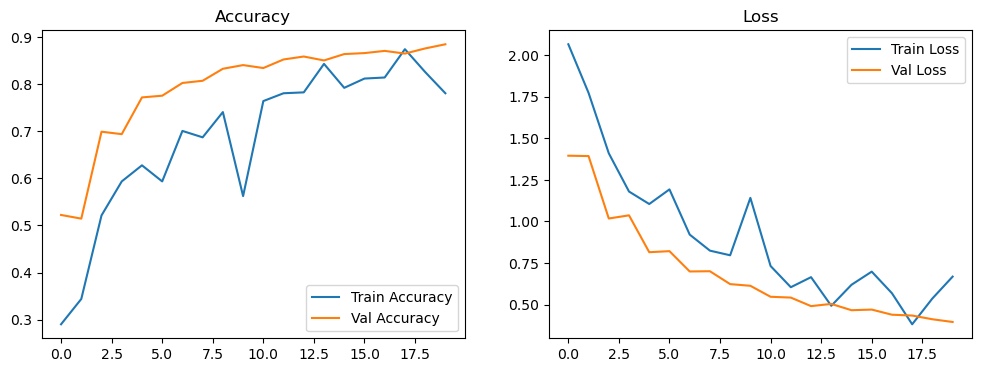

61/61 ━━━━━━━━━━━━━━━━━━━━ 106s 2s/step - accuracy: 0.8913 - loss: 0.3955
Validation Accuracy: 89.13%


In [5]:
# Train
epochs = 20  
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size,
    epochs=epochs
)

# Plot accuracy/loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')
plt.show()

# Evaluate on validation
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

In [6]:
# save model After training
model.save('IT24102358_MobileNetV2.keras')  # Saves in current folder
print("Model saved successfully as 'IT24102358_MobileNetV2.keras'")

Model saved successfully as 'IT24102358_MobileNetV2.keras'


In [10]:
#fine-tune after initial training
base_model.trainable = True
 
# Recompile with lower learning rate
model.compile(optimizer=Adam(learning_rate=1e-5), 
              loss='categorical_crossentropy', 
              metrics=['accuracy'])

print("Model is now ready for fine-tuning with lower learning rate.")

Model is now ready for fine-tuning with lower learning rate.


Epoch 1/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 1227s 5s/step - accuracy: 0.7174 - loss: 0.8072 - val_accuracy: 0.7927 - val_loss: 0.5893
Epoch 2/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 72s 280ms/step - accuracy: 0.8438 - loss: 0.5067 - val_accuracy: 0.7854 - val_loss: 0.6047
Epoch 3/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 1045s 4s/step - accuracy: 0.8726 - loss: 0.3869 - val_accuracy: 0.7771 - val_loss: 0.6564
Epoch 4/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 37s 143ms/step - accuracy: 0.9375 - loss: 0.3990 - val_accuracy: 0.7875 - val_loss: 0.6102
Epoch 5/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 1072s 4s/step - accuracy: 0.9100 - loss: 0.2678 - val_accuracy: 0.7828 - val_loss: 0.6615
Epoch 6/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 61s 234ms/step - accuracy: 0.9688 - loss: 0.1697 - val_accuracy: 0.7740 - val_loss: 0.6958
Epoch 7/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 1038s 4s/step - accuracy: 0.9314 - loss: 0.2044 - val_accuracy: 0.7708 - val_loss: 0.6991
Epoch 8/10
244/244 ━━━━━━━━━━━━━━━━━━━━ 65s 250ms/step - accuracy: 0.7812 - loss: 0.431

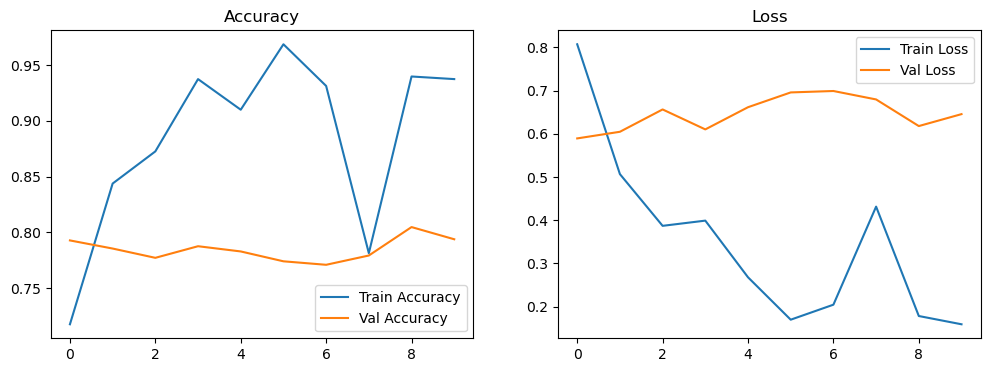

61/61 ━━━━━━━━━━━━━━━━━━━━ 62s 1s/step - accuracy: 0.7959 - loss: 0.6494
Validation Accuracy: 79.59%


In [11]:
# Train
epochs = 10  
history = model.fit(
    train_generator,
    steps_per_epoch=train_generator.samples // batch_size,
    validation_data=validation_generator,
    validation_steps=validation_generator.samples // batch_size,
    epochs=epochs
)

# Plot accuracy/loss
plt.figure(figsize=(12, 4))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Val Accuracy')
plt.legend()
plt.title('Accuracy')

plt.subplot(1, 2, 2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.legend()
plt.title('Loss')
plt.show()

# Evaluate on validation
val_loss, val_acc = model.evaluate(validation_generator)
print(f"Validation Accuracy: {val_acc * 100:.2f}%")

In [12]:
# save model After training
model.save('IT24102358_MobileNetV2.keras')  # Saves in current folder
print("Model saved successfully as 'IT24102358_MobileNetV2.keras'")

Model saved successfully as 'IT24102358_MobileNetV2.keras'


In [13]:
# Load model if saved
# model = tf.keras.models.load_model

# Predict function
def predict_image(img_path, threshold=0.7):  # Add threshold param
    img = image.load_img(img_path, target_size=(img_height, img_width))
    img_array = image.img_to_array(img)
    img_array = np.expand_dims(img_array, axis=0) / 255.0
    prediction = model.predict(img_array)[0]  # Get probabilities
    max_prob = np.max(prediction)
    if max_prob < threshold:
        return "Not a plant leaf (Confidence too low: {:.2f})".format(max_prob)
    class_idx = np.argmax(prediction)
    class_label = classes[class_idx]
    return f"{class_label} (Confidence: {max_prob:.2f})"
# Test
print(predict_image('test.jpg'))  # Replace with your test image path

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
Tomato_healthy (Confidence: 0.89)


In [14]:
def classify_leaf(image, threshold=0.7):
    img_array = np.array(image.resize((img_height, img_width)))
    img_array = np.expand_dims(img_array, axis=0) / 255.0
    prediction = model.predict(img_array)[0]
    max_prob = np.max(prediction)
    if max_prob < threshold:
        return f"Not a plant leaf or unknown (Low confidence: {max_prob:.2f})"
    class_idx = np.argmax(prediction)
    class_label = classes[class_idx]
    if 'healthy' in class_label.lower():
        return f"Healthy: {class_label} (Confidence: {max_prob:.2f})"
    else:
        return f"Diseased: {class_label} (Confidence: {max_prob:.2f})"

# Update interface to include threshold (optional slider)
iface = gr.Interface(
    fn=classify_leaf,
    inputs=[gr.Image(type="pil"), gr.Slider(0.5, 0.9, value=0.7, label="Confidence Threshold")],
    outputs="text",
    title="Plant Disease Detector",
    description="Upload a leaf image. Adjust threshold for stricter OOD detection."
)
iface.launch(share=False)

Running on local URL:  http://127.0.0.1:7860

To create a public link, set `share=True` in `launch()`.


C:\Users\USER\AppData\Roaming\Python\Python312\site-packages\gradio\analytics.py:106: UserWarning: IMPORTANT: You are using gradio version 4.44.0, however version 4.44.1 is available, please upgrade. 
--------
  warnings.warn(


In [15]:
from tensorflow.keras.models import load_model

# Load the saved model
model = load_model('IT24102358_MobileNetV2.keras')
print("Model loaded successfully")

Model loaded successfully
1/1 ━━━━━━━━━━━━━━━━━━━━ 5s 5s/step
